# 07 — Functional-Form Sensitivity and Galaxy-Grouped Cross-Validation (SPARC only)

**Project:** *Is the RAR Universal? Correlated-error-aware constraints on the scatter and acceleration scale of the radial acceleration relation in SPARC and independent HI samples*

This notebook completes two items the proposal requires:

1. **Alternative functional form (Sec. 4.1, citing Desmond, Bartlett & Ferreira 2023).** That paper compares several forms and concludes that SPARC alone cannot fix the RAR's shape; it does not recommend one. Two of its forms are fitted here:
   * **Double power law** (Lelli et al. 2017), g_obs = θ₁ (1 + g_bar/θ₀)^(θ₂−θ₃) (g_bar/θ₀)^θ₃. Its high- and low-acceleration slopes θ₂ and θ₃ are free, so it is the most direct test of whether a result depends on the assumed shape.
   * **"Simple" interpolating function** (Famaey & Binney 2005), g_obs = g_bar/2 + √(g_bar²/4 + g_bar g₀). This is the canonical MOND form, with no free shape.

   Both are fitted as a baseline and with **dependence on baryonic mass**, where the β and a₀ "hints" remained after Notebook 06. If the a₀ or shape trend with mass vanishes or reverses under a different form, it was a functional-form effect, not galaxy physics.
2. **Five-fold galaxy-grouped cross-validation (Sec. 4.7).** All points of a galaxy are in the same fold, and models are scored by the held-out log predictive density. Each held-out galaxy's distance, inclination and Υ★ are integrated over their priors, as in Notebooks 04–05. The compared models are the generalised RAR, double power law and simple IF baselines, and the generalised RAR with mass dependence. CV is supplementary to the PSIS-LOO results, as the proposal states.

**Unchanged from Notebook 05:** data (153 galaxies, 3,164 points), the Model C error treatment (independent errors with sampled D, i, Υ★), the σ_int and τ priors, the nuisance priors and the covariate definitions. The generalised-RAR code path reproduces Notebook 05 exactly, and this is tested.

**Correlated errors (Models D/E)** are not refitted here because each such fit takes hours. Notebook 06 already showed that the Model C population trends are not robust to correlated noise. This notebook asks the remaining question: are the β/a₀ hints shape artefacts?

**Runtime:** about 1–1.5 h on Colab. Results are saved as they finish, and an interrupted run can be resumed with `RAR_RESUME_FROM` (Section 2).

## 2. Environment and Configuration

In [1]:
import os, sys, importlib.util, subprocess
N_CPU = os.cpu_count() or 1
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={max(1, min(N_CPU, 8))}"
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = os.path.isdir("/kaggle/working")
REQUIRED = {"jax": "jax", "numpyro": "numpyro", "xarray": "xarray", "h5netcdf": "h5netcdf", "h5py": "h5py",
            "scipy": "scipy", "matplotlib": "matplotlib", "pandas": "pandas", "mpmath": "mpmath"}
missing = [p for m, p in REQUIRED.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import re, json, time, glob, hashlib, logging, platform, warnings, resource, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, scipy, scipy.stats as sst, xarray as xr
import matplotlib, matplotlib.pyplot as plt
import jax, jax.numpy as jnp
from jax.scipy.linalg import cholesky as jcholesky, solve_triangular
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value
from numpyro.infer.util import log_density, unconstrain_fn
from jax.scipy.special import ndtr, ndtri
from numpyro.diagnostics import split_gelman_rubin, effective_sample_size
numpyro.enable_x64()
numpyro.set_host_device_count(max(1, min(N_CPU, 8)))

RUN_TIMESTAMP = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
RUN_ID = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
            "jax": jax.__version__, "numpyro": numpyro.__version__, "xarray": xr.__version__, "matplotlib": matplotlib.__version__,
            "cpu_count": N_CPU, "jax_devices": len(jax.devices()), "jax_backend": jax.default_backend(), "x64": bool(jax.config.read("jax_enable_x64"))}
print(f"Run {RUN_ID} | Colab: {IN_COLAB}"); print(VERSIONS)

Run 20261028T085455Z | Colab: True
{'python': '3.13.18', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'jax': '0.11.1', 'numpyro': '0.22.0', 'xarray': '2025.12.0', 'matplotlib': '3.10.0', 'cpu_count': 2, 'jax_devices': 2, 'jax_backend': 'cpu', 'x64': True}


In [2]:
# =====================================================================
# CONFIGURATION
# =====================================================================
DRIVE_MOUNT_POINT = Path("/content/drive"); DRIVE_ROOT = DRIVE_MOUNT_POINT / "MyDrive"
PROJECT_ROOT = Path(os.environ.get("RAR_PROJECT_ROOT", str(DRIVE_ROOT / "RAR_Universality_Research")))
if IN_KAGGLE and "RAR_PROJECT_ROOT" not in os.environ:          # optional: also runs unattended on Kaggle
    import shutil
    cands = [p.parent for p in Path("/kaggle/input").rglob("03_Processed_Data") if p.is_dir()]
    full = [c for c in cands if any((c / "05_Results" / "Posterior_Samples").glob("03_bayesian_full_modelC_posterior*.nc"))]
    if not (full or cands): raise FileNotFoundError("Add your RAR_Universality_Research dataset as a Kaggle input.")
    src = sorted(full or cands, key=lambda p: len(p.parts))[0]
    PROJECT_ROOT = Path("/kaggle/working/RAR_Universality_Research")
    if not PROJECT_ROOT.exists(): shutil.copytree(src, PROJECT_ROOT, ignore=shutil.ignore_patterns("01_Datasets"))
PROC = PROJECT_ROOT / "03_Processed_Data"
DIRS = {"processed": PROC, "models": PROJECT_ROOT / "04_Trained_Models", "tables": PROJECT_ROOT / "05_Results" / "Tables",
        "posterior": PROJECT_ROOT / "05_Results" / "Posterior_Samples", "logs": PROC / "logs"}           # read-only inputs
NB02 = {"points": PROC / "sparc_rar_points_baseline.csv", "galaxies": PROC / "sparc_rar_galaxies_baseline.csv", "npz": PROC / "sparc_rar_model_inputs.npz"}
AUDIT01 = PROC / "sparc_galaxy_audit.csv"            # Notebook 01: derived Mbar and gas fraction (documented fiducial definitions)
NB03_RUN_ID = os.environ.get("RAR_NB03_RUN_ID", "")
OUT_ROOT = PROJECT_ROOT / "05_Results" / "Validation" / RUN_ID                  # new, versioned; never overwrites
NB05_DIR = PROJECT_ROOT / "05_Results" / "Population_Dependence"                   # read-only
OUT = {k: OUT_ROOT / k for k in ("posterior", "tables", "figures", "diagnostics", "config", "logs")}

KPC_IN_M, KMS_IN_MS, LN10 = 3.0856775814913673e19, 1.0e3, float(np.log(10.0))
REF = {"a0": 1.20e-10, "beta": 0.5, "upsilon_disk": 0.5, "upsilon_bulge": 0.7}
UPS_SIGMA_DEX = {"D": 0.10, "E": 0.20}             # Model C uses the 0.10 dex width (verified against Notebook 03)

# ---------------- Population model (proposal Sec. 4.5) ----------------
COVARIATES = {   # name: (definition, source)
    "logMbar": ("log10 baryonic mass [Msun] = log10(1.33 M_HI + 0.5 L[3.6]); Notebook 01 fiducial definition", "sparc_galaxy_audit.csv"),
    "logSB0":  ("log10 central disk surface brightness at 3.6 um [Lsun/pc^2] (SPARC SBdisk)", "sparc_rar_galaxies_baseline.csv"),
    "fgas":    ("gas fraction 1.33 M_HI / Mbar (Notebook 01 fiducial definition)", "sparc_galaxy_audit.csv"),
}
POP_PARAMS = ["log10_a0", "beta", "log_sigma_int", "log_tau"]
# Slope priors (per 1 SD of the covariate). They are not specified by the proposal: weakly informative regularisation choices,
# with a x2 sensitivity test. The intercepts (values at the sample-mean property) keep Notebook 03's priors exactly.
SLOPE_PRIOR_SD = {"log10_a0": 0.25,      # dex of a0 per SD
                  "beta": 0.10,          # beta per SD
                  "log_sigma_int": 0.5,  # natural-log units per SD (x1.65 per SD at 1 sigma)
                  "log_tau": 0.5}
BETA_FLOOR = 0.01                         # beta_i <= floor is outside the RAR's domain (zero likelihood); reported if ever approached
FITS_ONE_AT_A_TIME = list(COVARIATES)     # primary analysis
RUN_JOINT_FIT = True                      # secondary analysis (all three covariates together)
RUN_PRIOR_SENSITIVITY = False
# ---------------- Functional forms (Sec. 4.1 sensitivity; Desmond, Bartlett & Ferreira 2023) ----------------
FORMS = ["gen", "dpl", "simple"]          # generalised RAR (primary), double power law, simple interpolating function
# Priors for the alternative forms (not specified by the proposal; broad, documented choices):
ALT_PRIORS = {"log10_g0": (-11.5, -8.5),    # simple IF acceleration scale [m s^-2], same support as log10 a0
              "log10_t0": (-11.5, -8.5),    # DPL transition acceleration
              "c_dpl": (-1.0, 1.0),         # log10(theta1/theta0): normalisation in dex
              "t2_dpl": (0.5, 1.5),         # DPL high-acceleration slope (Newtonian: 1)
              "t3_dpl": (0.0, 1.0)}         # DPL low-acceleration slope (deep-MOND: 0.5)
DEP_COV = "logMbar"                        # dependence tested under every form (where the Notebook 06 hints remain)
FULL_FITS = [(f, dep) for f in FORMS for dep in (False, True)]
# ---------------- Cross-validation (Sec. 4.7) ----------------
CV_FOLDS, CV_SEED = 5, 20261028
CV_MODELS = [("gen", False), ("gen", True), ("dpl", False), ("simple", False)]
CV_FIT = {"chains": int(os.environ.get("RAR_CV_CHAINS", 2)), "warmup": int(os.environ.get("RAR_CV_WARMUP", 500)),
          "samples": int(os.environ.get("RAR_CV_SAMPLES", 750))}
CV_PRED = {"post_draws": int(os.environ.get("RAR_CV_DRAWS", 300)), "mc": int(os.environ.get("RAR_CV_MC", 48))}
RUN_CV = os.environ.get("RAR_RUN_CV", "1") == "1"
RESUME_FROM = os.environ.get("RAR_RESUME_FROM", "")      # earlier 07 run folder to resume from ("" = fresh)
FAMILY_ALPHA = 0.05                       # family-wise error rate over the declared test family (12 slopes)

# ---------------- Sampler (Notebook 03 settings; Model C converged with them) ----------------
SEED = 20261027
TARGET_ACCEPT, MAX_TREE_DEPTH = 0.90, 10
FIT = {"chains": int(os.environ.get("RAR_CHAINS", 4)), "warmup": int(os.environ.get("RAR_WARMUP", 1000)), "samples": int(os.environ.get("RAR_SAMPLES", 1500))}
RHAT_MAX, ESS_BULK_MIN, ESS_TAIL_MIN, DIVERGENCES_MAX, BFMI_MIN = 1.01, 400, 400, 0, 0.3
ILOO = {"post_draws": int(os.environ.get("RAR_ILOO_DRAWS", 300)), "mc": int(os.environ.get("RAR_ILOO_MC", 64))}
ALLOW_OVERWRITE = False
PROGRESS = not IN_KAGGLE
print("Project root:", PROJECT_ROOT); print("Outputs ->", OUT_ROOT)

Project root: /content/drive/MyDrive/RAR_Universality_Research
Outputs -> /content/drive/MyDrive/RAR_Universality_Research/05_Results/Validation/20261028T085455Z


## 3. Drive, Logging and Notebook 03 Inputs

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT_POINT))
if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_ROOT}")
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
if OUT_ROOT.exists() and any(OUT_ROOT.iterdir()):
    raise FileExistsError(f"{OUT_ROOT} already exists and is not empty; refusing to overwrite")
for d in OUT.values():
    d.mkdir(parents=True, exist_ok=True)
LOG_PATH = OUT["logs"] / f"07_validation_{RUN_ID}.log"
logging.raiseExceptions = False        # a Drive hiccup on the log file must not interrupt the run
logger = logging.getLogger("rar07"); logger.setLevel(logging.INFO); logger.handlers.clear(); logger.propagate = False
_fh = logging.FileHandler(LOG_PATH, encoding="utf-8"); _fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout); _sh.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
logger.addHandler(_fh); logger.addHandler(_sh)

CHECKS = []
def record_check(section, name, passed, detail="", severity="critical"):
    status = "PASS" if passed else ("FAIL" if severity == "critical" else "WARN")
    CHECKS.append({"section": section, "check": name, "status": status, "severity": severity, "detail": str(detail)})
    (logger.info if passed else (logger.error if severity == "critical" else logger.warning))(f"[{status}] {section} | {name} | {detail}")
    if status == "FAIL":
        raise RuntimeError(f"Critical check failed: {section} | {name} | {detail}")
    return bool(passed)

def safe_path(path: Path) -> Path:
    if path.exists() and not ALLOW_OVERWRITE:
        new = path.with_name(f"{path.stem}_{RUN_ID}{path.suffix}"); logger.info(f"{path.name} exists; writing {new.name}"); return new
    return path

def sha256_of(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()
print("Log:", LOG_PATH)

Mounted at /content/drive
Log: /content/drive/MyDrive/RAR_Universality_Research/05_Results/Validation/20261028T085455Z/logs/07_validation_20261028T085455Z.log


In [4]:
cfgs = []
for p in sorted(DIRS["models"].glob("03_bayesian_sampler_config*.json")):
    try:
        c = json.loads(p.read_text()); cm = c.get("full", {}).get("completed_models", {})
        cfgs.append({"file": p.name, "run_id": c.get("run_id"), "created": c.get("created_utc"), "full_models": ",".join(cm), "cfg": c})
    except Exception as exc:
        logger.warning(f"Could not read {p.name}: {exc}")
cfg_table = pd.DataFrame(cfgs)
display(cfg_table.drop(columns="cfg") if len(cfg_table) else "no Notebook 03 configurations found")
cands = [c for c in cfgs if "C" in c["full_models"].split(",") and (not NB03_RUN_ID or c["run_id"] == NB03_RUN_ID)]
record_check("NB03", "a Notebook 03 run with a completed full Model C exists", bool(cands), f"{len(cands)} candidate runs")
nb03 = max(cands, key=lambda c: c["created"]); CFG03 = nb03["cfg"]; RUN03 = nb03["run_id"]
print(f"Using Notebook 03 run {RUN03} (config {nb03['file']})")

def run_file(folder, stem, ext):
    # File written by run RUN03: suffixed name if present, else the base name.
    p1 = folder / f"{stem}_{RUN03}{ext}"; p0 = folder / f"{stem}{ext}"
    return p1 if p1.is_file() else p0

NC03 = {}
for m, info in CFG03["full"]["completed_models"].items():
    p = Path(info["netcdf"])
    if not p.is_file():                                         # stored path may be absolute from another mount; fall back to folder
        p = DIRS["posterior"] / Path(info["netcdf"]).name
    record_check("NB03", f"Model {m} posterior file exists", p.is_file(), str(p))
    attrs = xr.open_dataset(p, group="posterior", engine="h5netcdf").attrs
    record_check("NB03", f"Model {m} posterior carries run ID {RUN03}", attrs.get("run_id") == RUN03, f"file run_id {attrs.get('run_id')}")
    st = info["stats"]
    record_check("NB03", f"Model {m} met all convergence criteria in Notebook 03", bool(st["converged_by_all_criteria"]),
                 f"max R-hat {st['max_r_hat_all']:.4f}, min ESS {st['min_ess_bulk_all']:.0f}, divergences {st['divergences']}",
                 severity="warning" if os.environ.get("RAR_TEST_ALLOW_UNCONVERGED_NB03") == "1" else "critical")   # override: local testing only
    NC03[m] = p
chk03_path = run_file(DIRS["processed"], "03_bayesian_integrity_checks", ".csv")
chk03 = pd.read_csv(chk03_path)
record_check("NB03", "Notebook 03 check register has no FAIL rows", int((chk03.status == "FAIL").sum()) == 0,
             f"{chk03_path.name}: {len(chk03)} checks, {int((chk03.status=='FAIL').sum())} FAIL, {int((chk03.status=='WARN').sum())} WARN")
print("Notebook 03 warnings:"); display(chk03[chk03.status == "WARN"][["section", "check", "detail"]])
comp03_path = run_file(DIRS["tables"], "03_bayesian_model_comparison", ".csv")
comp03 = pd.read_csv(comp03_path) if comp03_path.is_file() else pd.DataFrame()
if len(comp03):
    display(comp03[[c for c in comp03.columns if c in ("stage", "model", "elpd_loo_galaxy", "p_loo", "n_pareto_k_gt_0.7", "sigma_int_median", "tau_median")]])
    bad_k = comp03[(comp03.get("n_pareto_k_gt_0.7", 0) > 0.1 * comp03.get("n_galaxies", 1))]
    record_check("NB03", "Notebook 03 galaxy-level PSIS-LOO reliable (Pareto k > 0.7 in < 10% of galaxies)", bad_k.empty,
                 bad_k[["stage", "model", "n_pareto_k_gt_0.7"]].values.tolist() if not bad_k.empty else "ok", severity="warning")

# Shared priors must be identical to Notebook 03
P03 = CFG03["priors"]
same_priors = (P03["log10_a0"]["low"] == -11.5 and P03["log10_a0"]["high"] == -8.5 and P03["beta"]["low"] == 0.05 and P03["beta"]["high"] == 1.0
               and P03["sigma_int"]["scale"] == 0.1 and P03["tau"]["scale"] == 0.1 and P03["upsilon_disk"]["sigma_dex"] == UPS_SIGMA_DEX["D"]
               and P03["upsilon_disk"]["median"] == REF["upsilon_disk"] and P03["upsilon_bulge"]["median"] == REF["upsilon_bulge"]
               and P03["inclination"]["low"] == 1.0 and P03["inclination"]["high"] == 90.0)
record_check("NB03", "shared priors in this notebook equal Notebook 03's saved priors", same_priors, "log10_a0, beta, sigma_int, tau, Upsilon, inclination bounds")
record_check("NB03", "Sigma_x convention unchanged (0: no documented baryonic-component errors)", CFG03.get("sigma_x_log_gbar", None) == 0.0, "0.0")

,file,run_id,created,full_models
0,03_bayesian_sampler_config.json,20261022T095219Z,2026-10-22T09:52:19Z,
1,03_bayesian_sampler_config_20261022T095735Z.json,20261022T095735Z,2026-10-22T09:57:35Z,"C,A,B"


INFO: [PASS] NB03 | a Notebook 03 run with a completed full Model C exists | 1 candidate runs
Using Notebook 03 run 20261022T095735Z (config 03_bayesian_sampler_config_20261022T095735Z.json)
INFO: [PASS] NB03 | Model C posterior file exists | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_full_modelC_posterior.nc
INFO: [PASS] NB03 | Model C posterior carries run ID 20261022T095735Z | file run_id 20261022T095735Z
INFO: [PASS] NB03 | Model C met all convergence criteria in Notebook 03 | max R-hat 1.0014, min ESS 2962, divergences 0
INFO: [PASS] NB03 | Model A posterior file exists | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_full_modelA_posterior.nc
INFO: [PASS] NB03 | Model A posterior carries run ID 20261022T095735Z | file run_id 20261022T095735Z
INFO: [PASS] NB03 | Model A met all convergence criteria in Notebook 03 | max R-hat 1.0026, min ESS 1913, divergences 0
INFO: [PASS] NB03 | Model B poste

,section,check,detail
17,Positivity,every point excluded by the rule was also non-...,"rule excludes [('DDO064', 0), ('UGC01281', 0),..."


,stage,model,elpd_loo_galaxy,p_loo,n_pareto_k_gt_0.7,sigma_int_median,tau_median
0,PILOT (validation only),C,135.761034,58.684227,5,0.060355,0.186125
1,FULL,A,3084.192629,47.431458,3,0.057298,0.155636
2,FULL,B,3151.837121,64.228407,4,0.045952,0.147108
3,FULL,C,3661.801975,379.460001,88,0.035569,0.121956


INFO: [PASS] NB03 | shared priors in this notebook equal Notebook 03's saved priors | log10_a0, beta, sigma_int, tau, Upsilon, inclination bounds
INFO: [PASS] NB03 | Sigma_x convention unchanged (0: no documented baryonic-component errors) | 0.0


True

In [5]:
for k in ("points", "galaxies", "npz"):
    rec = CFG03["input_checksums"].get(NB02[k].name)
    record_check("Sample", f"{NB02[k].name} unchanged since Notebook 03", rec is not None and sha256_of(NB02[k]) == rec, "SHA-256 compared")
pts = pd.read_csv(NB02["points"]); gals = pd.read_csv(NB02["galaxies"])
npz = np.load(NB02["npz"])
p_sorted = pts.sort_values(["galaxy_index", "point_index"]).reset_index(drop=True)
gtab = gals.sort_values("galaxy_index").reset_index(drop=True)
G = len(gtab); gi = p_sorted.galaxy_index.to_numpy(np.int32)
R0, V0, eV0 = npz["R_kpc"], npz["Vobs_kms"], npz["errV_kms"]
Vg0, Vd0, Vb0 = npz["Vgas_kms"], npz["Vdisk_ups1_kms"], npz["Vbul_ups1_kms"]
D0, eD0 = gtab.distance_mpc.to_numpy(float), gtab.e_distance_mpc.to_numpy(float)
I0, eI0 = gtab.inc_deg.to_numpy(float), gtab.e_inc_deg.to_numpy(float)
has_bulge = p_sorted.groupby("galaxy_index").Vbul.apply(lambda s: bool((s > 0).any())).reindex(range(G)).to_numpy()

# Positivity rule exactly as Notebook 03 (same seed and draw count); E's wider prior is evaluated for information only
def positivity(sig_dex, seed, n):
    rng = np.random.default_rng(seed)
    ud = 10 ** (np.log10(REF["upsilon_disk"]) + sig_dex * rng.standard_normal(n))
    ub = 10 ** (np.log10(REF["upsilon_bulge"]) + sig_dex * rng.standard_normal(n))
    p = np.ones(len(R0))
    for k in np.where(Vg0 <= 0)[0]:
        p[k] = float(np.mean(ud * Vd0[k] ** 2 + ub * Vb0[k] ** 2 + Vg0[k] * abs(Vg0[k]) > 0))
    return p
pos = CFG03["positivity_rule"]
p_pos = positivity(UPS_SIGMA_DEX["D"], CFG03["seed"], pos["mc_draws"])
gbar_ref = (Vg0 * np.abs(Vg0) + 0.5 * Vd0 ** 2 + 0.7 * Vb0 ** 2)
include = (p_pos >= pos["P_prior_min"]) & (gbar_ref > 0)
excl = sorted(zip(p_sorted.galaxy[~include], p_sorted.point_index[~include].astype(int)))
record_check("Sample", f"point set reproduces Notebook 03 ({pos['n_points_included']} points)", int(include.sum()) == pos["n_points_included"], f"{int(include.sum())}")
record_check("Sample", "excluded points identical to Notebook 03", [list(map(lambda v: v if isinstance(v, str) else int(v), e)) for e in excl] == pos["excluded_points"], excl)


INFO: [PASS] Sample | sparc_rar_points_baseline.csv unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | sparc_rar_galaxies_baseline.csv unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | sparc_rar_model_inputs.npz unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | point set reproduces Notebook 03 (3164 points) | 3164
INFO: [PASS] Sample | excluded points identical to Notebook 03 | [('DDO064', 0), ('UGC01281', 0), ('UGC01281', 1), ('UGC07577', 0)]


True

## 4. Covariates and Likelihood (Notebook 05)

In [6]:
aud = pd.read_csv(AUDIT01)
cov = gtab[["galaxy", "galaxy_index", "SBdisk0_Lsun_pc2"]].merge(aud[["galaxy", "Mbar_1e9Msun_derived_fid", "fgas_derived_fid", "MHI_1e9Msun", "L36_1e9Lsun"]], on="galaxy", how="left")
cov["logMbar"] = np.log10(cov.Mbar_1e9Msun_derived_fid * 1e9)
cov["logSB0"] = np.log10(cov.SBdisk0_Lsun_pc2)
cov["fgas"] = cov.fgas_derived_fid
recheck = np.allclose(cov.Mbar_1e9Msun_derived_fid, 1.33 * cov.MHI_1e9Msun + 0.5 * cov.L36_1e9Lsun, rtol=1e-6)
record_check("Covariates", "Mbar reproduces 1.33 M_HI + 0.5 L[3.6] (Notebook 01 definition)", recheck, "")
record_check("Covariates", "galaxy order equals the model-input order", list(cov.galaxy_index) == list(range(G)), f"{G} galaxies")
for c in COVARIATES:
    record_check("Covariates", f"{c} finite for all {G} galaxies", bool(np.isfinite(cov[c]).all()), f"{int((~np.isfinite(cov[c])).sum())} non-finite")
COV_MEAN = {c: float(cov[c].mean()) for c in COVARIATES}; COV_SD = {c: float(cov[c].std(ddof=0)) for c in COVARIATES}
Zall = np.column_stack([(cov[c] - COV_MEAN[c]) / COV_SD[c] for c in COVARIATES])
cov_corr = pd.DataFrame(np.corrcoef(Zall.T), index=list(COVARIATES), columns=list(COVARIATES))
vif = {c: float(np.linalg.inv(cov_corr.values)[k, k]) for k, c in enumerate(COVARIATES)}
print("Covariate summary (physical units):"); display(cov[list(COVARIATES)].describe().T)
print("Correlation matrix of the standardised covariates:"); display(cov_corr.round(3))
print("Variance inflation factors (joint fit):", {k: round(v, 2) for k, v in vif.items()})
if max(vif.values()) > 2.5:
    logger.warning("Covariates are strongly correlated: joint-fit slopes will be partly degenerate. The one-at-a-time fits are primary (declared).")
cov_table = cov[["galaxy", "logMbar", "logSB0", "fgas"]].assign(**{f"z_{c}": Zall[:, k] for k, c in enumerate(COVARIATES)})

INFO: [PASS] Covariates | Mbar reproduces 1.33 M_HI + 0.5 L[3.6] (Notebook 01 definition) | 
INFO: [PASS] Covariates | galaxy order equals the model-input order | 153 galaxies
INFO: [PASS] Covariates | logMbar finite for all 153 galaxies | 0 non-finite
INFO: [PASS] Covariates | logSB0 finite for all 153 galaxies | 0 non-finite
INFO: [PASS] Covariates | fgas finite for all 153 galaxies | 0 non-finite
Covariate summary (physical units):


,count,mean,std,min,25%,50%,75%,max
logMbar,153.0,9.827318,0.949282,7.690728,9.215529,9.785799,10.663295,11.429540
logSB0,153.0,2.642165,0.689011,1.324899,2.060849,2.592832,3.172831,4.376830
fgas,153.0,0.449970,0.271471,0.015500,0.185615,0.443737,0.678258,0.945325


Correlation matrix of the standardised covariates:


,logMbar,logSB0,fgas
logMbar,1.000,0.659,-0.769
logSB0,0.659,1.000,-0.742
fgas,-0.769,-0.742,1.000


Variance inflation factors (joint fit): {'logMbar': 2.56, 'logSB0': 2.32, 'fgas': 3.21}


In [7]:
def accelerations(D, inc_deg, ups_d, ups_b, idx, R0, V0, eV0, Vg0, Vd0, Vb0, D0, I0, xp=jnp):
    sD = (D / D0)[idx]
    s_inc = (xp.sin(xp.deg2rad(I0)) / xp.sin(xp.deg2rad(inc_deg)))[idx]
    R_m = R0 * sD * KPC_IN_M
    Vobs, eV = V0 * s_inc, eV0 * s_inc
    vbar2 = (Vg0 * xp.abs(Vg0) + ups_d[idx] * Vd0 ** 2 + ups_b[idx] * Vb0 ** 2) * sD
    g_obs = (Vobs * KMS_IN_MS) ** 2 / R_m
    g_bar = vbar2 * KMS_IN_MS ** 2 / R_m
    sig_V = 2.0 * eV / (Vobs * LN10)
    return g_obs, g_bar, sig_V

def f_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return x - jnp.log10(-jnp.expm1(-t))

def fprime_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return 1.0 - beta * t * jnp.exp(-t) / (-jnp.expm1(-t))

def residual_terms(params, data, nuis):
    log10_a0, beta = params[0], params[1]
    D, inc, ud, ub = nuis
    g_obs, g_bar, sig_V = accelerations(D, inc, ud, ub, data["idx"], data["R0"], data["V0"], data["eV0"],
                                        data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    pos = g_bar > 0
    x = jnp.log10(jnp.where(pos, g_bar, 1e-10)); y = jnp.log10(g_obs)
    mu = f_rar(x, log10_a0, beta)
    return y - mu, sig_V, x, y, mu, pos

def galaxy_loglik_C(params, data, nuis):
    # Notebook 03 Model C likelihood (Sherman-Morrison, delta_i marginalised).
    log10_a0, beta, sig_int, tau, s = params
    r, sig_V, x, _, _, pos = residual_terms(params, data, nuis)
    d = (s * sig_V) ** 2 + (fprime_rar(x, log10_a0, beta) * data["sigx"]) ** 2 + sig_int ** 2
    seg = lambda v: jax.ops.segment_sum(v, data["idx"], num_segments=data["G"])
    S, A, Q, L, n = seg(1 / d), seg(r / d), seg(r ** 2 / d), seg(jnp.log(d)), seg(jnp.ones_like(d))
    ll = -0.5 * (Q - tau ** 2 * A ** 2 / (1 + tau ** 2 * S) + L + jnp.log1p(tau ** 2 * S) + n * jnp.log(2 * jnp.pi))
    return ll, jnp.all(pos)

def build_data_C(mask_points):
    rows = np.where(np.asarray(mask_points, bool))[0]
    gal_ids = np.unique(gi[rows]); remap = -np.ones(G, int); remap[gal_ids] = np.arange(len(gal_ids))
    idx = remap[gi[rows]]; Gs = len(gal_ids); bulge_local = np.where(has_bulge[gal_ids])[0]
    return {"idx": jnp.asarray(idx), "G": Gs, "gal_ids": gal_ids, "rows": rows, "bulge_local": jnp.asarray(bulge_local), "n_bulge": len(bulge_local),
            **{k: jnp.asarray(v[rows]) for k, v in dict(R0=R0, V0=V0, eV0=eV0, Vg0=Vg0, Vd0=Vd0, Vb0=Vb0).items()},
            "D0": jnp.asarray(D0[gal_ids]), "eD0": jnp.asarray(eD0[gal_ids]), "I0": jnp.asarray(I0[gal_ids]), "eI0": jnp.asarray(eI0[gal_ids]),
            "sigx": jnp.zeros(len(rows))}

def galaxy_loglik_pop(a_g, b_g, s_g, t_g, data, nuis):
    # Model C likelihood with per-galaxy log10 a0, beta, sigma_int, tau (arrays of length G).
    D, inc, ud, ub = nuis; idx = data["idx"]
    g_obs, g_bar, sig_V = accelerations(D, inc, ud, ub, idx, data["R0"], data["V0"], data["eV0"], data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    pos = g_bar > 0
    x = jnp.log10(jnp.where(pos, g_bar, 1e-10)); y = jnp.log10(g_obs)
    a_p, b_p = a_g[idx], b_g[idx]
    r = y - f_rar(x, a_p, b_p)
    d = sig_V ** 2 + (fprime_rar(x, a_p, b_p) * data["sigx"]) ** 2 + s_g[idx] ** 2
    seg = lambda v: jax.ops.segment_sum(v, idx, num_segments=data["G"])
    S, A, Q, L, n = seg(1 / d), seg(r / d), seg(r ** 2 / d), seg(jnp.log(d)), seg(jnp.ones_like(d))
    ll = -0.5 * (Q - t_g ** 2 * A ** 2 / (1 + t_g ** 2 * S) + L + jnp.log1p(t_g ** 2 * S) + n * jnp.log(2 * jnp.pi))
    return ll, jnp.all(pos)

include_mask = include
data_full = build_data_C(include_mask)
Z_full = jnp.asarray(Zall[data_full["gal_ids"]])
print(f"Data: {data_full['G']} galaxies, {len(data_full['rows'])} points")

Data: 153 galaxies, 3164 points


In [8]:
ds_post = xr.open_dataset(NC03["C"], group="posterior", engine="h5netcdf")
ds_ll = xr.open_dataset(NC03["C"], group="log_likelihood", engine="h5netcdf")
names_nc = [str(x) for x in ds_post.galaxy.values]; names_here = list(gtab.galaxy.to_numpy()[data_full["gal_ids"]])
record_check("Regression", "Notebook 03 Model C galaxy order equals this notebook's", names_nc == names_here, f"{len(names_nc)} galaxies")
bulge_pos = [names_here.index(str(n)) for n in ds_post.bulge_galaxy.values] if "bulge_galaxy" in ds_post.dims else []
def nuis_from_nc(ds, c, d):
    ub = np.full(data_full["G"], REF["upsilon_bulge"])
    if bulge_pos: ub[bulge_pos] = ds["ups_bulge"].values[c, d]
    return (jnp.asarray(ds["D"].values[c, d]), jnp.asarray(ds["inc"].values[c, d]), jnp.asarray(ds["ups_disk"].values[c, d]), jnp.asarray(ub))
rng = np.random.default_rng(SEED); nchain, ndraw = ds_post.sizes["chain"], ds_post.sizes["draw"]; dev_saved, dev_C = 0.0, 0.0
for _ in range(10):
    c, d = int(rng.integers(nchain)), int(rng.integers(ndraw))
    th = [float(ds_post[k].values[c, d]) for k in ("log10_a0", "beta", "sigma_int", "tau")]
    nuis = nuis_from_nc(ds_post, c, d); Gn = data_full["G"]
    ll_p, _ = galaxy_loglik_pop(*(jnp.full(Gn, v) for v in th), data_full, nuis)
    ll_c, _ = galaxy_loglik_C((*th, 1.0), data_full, nuis)
    dev_saved = max(dev_saved, float(np.max(np.abs(np.asarray(ll_p) - ds_ll["galaxy_loglik"].values[c, d]))))
    dev_C = max(dev_C, float(np.max(np.abs(np.asarray(ll_p) - np.asarray(ll_c)))))
record_check("Regression", "zero-slope likelihood = Notebook 03 saved Model C log-likelihoods (10 draws, all galaxies)", dev_saved < 1e-6, f"max |diff| = {dev_saved:.2e}")
record_check("Regression", "zero-slope likelihood = Notebook 03 galaxy_loglik_C", dev_C < 1e-8, f"max |diff| = {dev_C:.2e}")
REGRESSION = {"max_abs_diff_vs_saved_NB03": dev_saved, "max_abs_diff_vs_C": dev_C}

INFO: [PASS] Regression | Notebook 03 Model C galaxy order equals this notebook's | 153 galaxies
INFO: [PASS] Regression | zero-slope likelihood = Notebook 03 saved Model C log-likelihoods (10 draws, all galaxies) | max |diff| = 2.37e-12
INFO: [PASS] Regression | zero-slope likelihood = Notebook 03 galaxy_loglik_C | max |diff| = 0.00e+00


## 5. Functional Forms and the General Population Model

The likelihood is Notebook 05's Sherman–Morrison likelihood, with the RAR mean replaced by the chosen form. Σ_x = 0, as in Notebooks 03–05, so the derivative of the mean is not needed. The test below asserts this. For the generalised RAR this code reproduces Notebook 05's `galaxy_loglik_pop` exactly.

**Dependence parameters** (mass dependence fits only): the acceleration scale (log₁₀ a₀ / log₁₀ θ₀ / log₁₀ g₀), the low-acceleration shape (β for the generalised RAR, θ₃ for the double power law; the simple IF has none), log σ_int and log τ. Slope priors are Notebook 05's: acceleration scale 0.25 dex per SD; shape 0.10 per SD; ln-scales 0.5 per SD.

In [9]:
record_check("Model", "Sigma_x is zero for all points (mean derivative not needed)", bool(np.all(np.asarray(data_full["sigx"]) == 0)), "Notebook 03 convention")
def mean_form(form, x, p):
    # log10 g_obs as a function of x = log10 g_bar; p: per-point parameter dict
    if form == "gen":
        return f_rar(x, p["loc"], p["shape"])
    if form == "simple":
        return x + jnp.log10(0.5 + jnp.sqrt(0.25 + 10 ** (p["loc"] - x)))
    if form == "dpl":
        u = x - p["loc"]
        return p["loc"] + p["c"] + (p["t2"] - p["shape"]) * jnp.log10(1 + 10 ** u) + p["shape"] * u
    raise ValueError(form)

def galaxy_loglik_form(form, pg, s_g, t_g, data, nuis):
    D, inc, ud, ub = nuis; idx = data["idx"]
    g_obs, g_bar, sig_V = accelerations(D, inc, ud, ub, idx, data["R0"], data["V0"], data["eV0"], data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    pos = g_bar > 0
    x = jnp.log10(jnp.where(pos, g_bar, 1e-10)); y = jnp.log10(g_obs)
    r = y - mean_form(form, x, {k: (v[idx] if jnp.ndim(v) else v) for k, v in pg.items()})
    d = sig_V ** 2 + s_g[idx] ** 2
    seg = lambda v: jax.ops.segment_sum(v, idx, num_segments=data["G"])
    S, A, Q, L, n = seg(1 / d), seg(r / d), seg(r ** 2 / d), seg(jnp.log(d)), seg(jnp.ones_like(d))
    ll = -0.5 * (Q - t_g ** 2 * A ** 2 / (1 + t_g ** 2 * S) + L + jnp.log1p(t_g ** 2 * S) + n * jnp.log(2 * jnp.pi))
    return ll, jnp.all(pos)

SLOPE_SD = {"loc": SLOPE_PRIOR_SD["log10_a0"], "shape": SLOPE_PRIOR_SD["beta"], "log_sigma_int": SLOPE_PRIOR_SD["log_sigma_int"], "log_tau": SLOPE_PRIOR_SD["log_tau"]}
def dep_params(form): return ["loc"] + (["shape"] if form in ("gen", "dpl") else []) + ["log_sigma_int", "log_tau"]

def form_globals(form):
    if form == "gen":
        return {"loc": numpyro.sample("log10_a0", dist.Uniform(P03["log10_a0"]["low"], P03["log10_a0"]["high"])),
                "shape": numpyro.sample("beta", dist.Uniform(P03["beta"]["low"], P03["beta"]["high"]))}
    if form == "simple":
        return {"loc": numpyro.sample("log10_g0", dist.Uniform(*ALT_PRIORS["log10_g0"]))}
    return {"loc": numpyro.sample("log10_t0", dist.Uniform(*ALT_PRIORS["log10_t0"])), "c": numpyro.sample("c_dpl", dist.Uniform(*ALT_PRIORS["c_dpl"])),
            "t2": numpyro.sample("t2_dpl", dist.Uniform(*ALT_PRIORS["t2_dpl"])), "shape": numpyro.sample("t3_dpl", dist.Uniform(*ALT_PRIORS["t3_dpl"]))}

def form_model(data, cfg):
    form, Z = cfg["form"], cfg["Z"]; K = Z.shape[1]
    g = form_globals(form)
    sig_int = numpyro.sample("sigma_int", dist.HalfNormal(P03["sigma_int"]["scale"]))
    tau = numpyro.sample("tau", dist.HalfNormal(P03["tau"]["scale"]))
    Gn = data["G"]; pg = {k: jnp.full(Gn, v) for k, v in g.items()}; s_g, t_g = jnp.full(Gn, sig_int), jnp.full(Gn, tau)
    if K:
        for p in dep_params(form):
            s = numpyro.sample(f"slope_{p}", dist.Normal(jnp.zeros(K), SLOPE_SD[p]).to_event(1)); lin = Z @ s
            if p in ("loc", "shape"): pg[p] = pg[p] + lin
            elif p == "log_sigma_int": s_g = s_g * jnp.exp(lin)
            else: t_g = t_g * jnp.exp(lin)
    with numpyro.plate("galaxies", Gn):                              # Notebook 03 Model C nuisance sampling, verbatim
        zD = numpyro.sample("zD", dist.Normal(0, 1))
        inc = numpyro.sample("inc", dist.TruncatedNormal(data["I0"], data["eI0"], low=P03["inclination"]["low"], high=P03["inclination"]["high"]))
        zUd = numpyro.sample("zUd", dist.Normal(0, 1))
    D = numpyro.deterministic("D", data["D0"] * jnp.exp(zD * data["eD0"] / data["D0"]))
    ud = numpyro.deterministic("ups_disk", P03["upsilon_disk"]["median"] * 10 ** (P03["upsilon_disk"]["sigma_dex"] * zUd))
    ub = jnp.full(Gn, REF["upsilon_bulge"])
    if data["n_bulge"] > 0:
        with numpyro.plate("bulge_galaxies", data["n_bulge"]):
            zUb = numpyro.sample("zUb", dist.Normal(0, 1))
        ub = ub.at[data["bulge_local"]].set(P03["upsilon_bulge"]["median"] * 10 ** (P03["upsilon_bulge"]["sigma_dex"] * zUb))
    ok_shape = (jnp.min(pg["shape"]) > BETA_FLOOR) if form == "gen" else True
    ll, ok = galaxy_loglik_form(form, pg, s_g, t_g, data, (D, inc, ud, ub))
    numpyro.factor("loglik", jnp.where(ok & ok_shape, jnp.sum(ll), -jnp.inf))

def make_cfg(form, dep, data, gal_ids):
    Z = jnp.asarray(Zall[gal_ids][:, [list(COVARIATES).index(DEP_COV)]]) if dep else jnp.zeros((data["G"], 0))
    return {"form": form, "dep": dep, "Z": Z, "name": f"{form}{'_dep_' + DEP_COV if dep else '_baseline'}"}

def init_form(form, dep, data):
    v = {"sigma_int": C_MED["sigma_int"], "tau": C_MED["tau"], "zD": jnp.zeros(data["G"]), "inc": jnp.clip(data["I0"], 2.0, 89.5), "zUd": jnp.zeros(data["G"])}
    if data["n_bulge"]: v["zUb"] = jnp.zeros(data["n_bulge"])
    v.update({"gen": {"log10_a0": C_MED["log10_a0"], "beta": C_MED["beta"]}, "simple": {"log10_g0": -9.9},
              "dpl": {"log10_t0": -9.9, "c_dpl": 0.0, "t2_dpl": 0.95, "t3_dpl": 0.45}}[form])
    if dep:
        for p in dep_params(form): v[f"slope_{p}"] = jnp.zeros(1)
    return v
C_MED = {k: float(np.median(ds_post[k].values)) for k in ("log10_a0", "beta", "sigma_int", "tau")}

# ---- tests: the generalised form reproduces Notebook 05 exactly; alternative forms behave as their formulas
rng = np.random.default_rng(SEED); nuis = nuis_from_nc(ds_post, 0, 5); Gn = data_full["G"]
th = [float(ds_post[k].values[0, 5]) for k in ("log10_a0", "beta", "sigma_int", "tau")]
ll5, _ = galaxy_loglik_pop(*(jnp.full(Gn, v) for v in th), data_full, nuis)
llg, _ = galaxy_loglik_form("gen", {"loc": jnp.full(Gn, th[0]), "shape": jnp.full(Gn, th[1])}, jnp.full(Gn, th[2]), jnp.full(Gn, th[3]), data_full, nuis)
record_check("Forms", "generalised RAR via the general code = Notebook 05 likelihood", float(np.max(np.abs(np.asarray(ll5) - np.asarray(llg)))) < 1e-10,
             f"max |diff| {float(np.max(np.abs(np.asarray(ll5) - np.asarray(llg)))):.1e}")
xg = jnp.linspace(-12.5, -8.0, 200); g = 10 ** xg; g0 = 1.2e-10
simple_ref = jnp.log10(g / 2 + jnp.sqrt(g ** 2 / 4 + g * g0))
record_check("Forms", "simple IF code = direct formula", float(jnp.max(jnp.abs(mean_form("simple", xg, {"loc": np.log10(g0)}) - simple_ref))) < 1e-12, "")
t0, t1, t2, t3 = 1.2e-10, 1.6e-10, 0.94, 0.6
dpl_ref = jnp.log10(t1 * (1 + g / t0) ** (t2 - t3) * (g / t0) ** t3)
record_check("Forms", "double power law code = direct formula (Lelli et al. 2017 eq.)", float(jnp.max(jnp.abs(mean_form("dpl", xg, {"loc": np.log10(t0), "c": np.log10(t1 / t0), "t2": t2, "shape": t3}) - dpl_ref))) < 1e-12, "")
record_check("Forms", "generalised RAR with beta = 0.5 equals the standard RAR IF of Lelli et al. 2017", float(jnp.max(jnp.abs(f_rar(xg, np.log10(g0), 0.5) - jnp.log10(g / (1 - jnp.exp(-jnp.sqrt(g / g0))))))) < 1e-12, "")
for form in FORMS:
    for dep in (False, True):
        c_ = make_cfg(form, dep, data_full, data_full["gal_ids"])
        lp, _ = log_density(form_model, (data_full, c_), {}, init_form(form, dep, data_full))
        record_check("Forms", f"{c_['name']}: log density finite at initial values", bool(np.isfinite(float(lp))), f"{float(lp):.1f}")

INFO: [PASS] Model | Sigma_x is zero for all points (mean derivative not needed) | Notebook 03 convention
INFO: [PASS] Forms | generalised RAR via the general code = Notebook 05 likelihood | max |diff| 0.0e+00
INFO: [PASS] Forms | simple IF code = direct formula | 
INFO: [PASS] Forms | double power law code = direct formula (Lelli et al. 2017 eq.) | 
INFO: [PASS] Forms | generalised RAR with beta = 0.5 equals the standard RAR IF of Lelli et al. 2017 | 
INFO: [PASS] Forms | gen_baseline: log density finite at initial values | 2037.5
INFO: [PASS] Forms | gen_dep_logMbar: log density finite at initial values | 2038.9
INFO: [PASS] Forms | dpl_baseline: log density finite at initial values | 1791.2
INFO: [PASS] Forms | dpl_dep_logMbar: log density finite at initial values | 1792.6
INFO: [PASS] Forms | simple_baseline: log density finite at initial values | 2105.3
INFO: [PASS] Forms | simple_dep_logMbar: log density finite at initial values | 2105.3


## 6. Sampling, Diagnostics and Resume Machinery

In [10]:
def run_fit(cfg, seed):
    kernel = NUTS(pop_model, target_accept_prob=TARGET_ACCEPT, max_tree_depth=MAX_TREE_DEPTH, init_strategy=init_to_value(values=init_values(cfg)))
    method = "parallel" if len(jax.devices()) >= FIT["chains"] else "sequential"
    mcmc = MCMC(kernel, num_warmup=FIT["warmup"], num_samples=FIT["samples"], num_chains=FIT["chains"], chain_method=method, progress_bar=PROGRESS)
    t0 = time.time()
    mcmc.run(jax.random.PRNGKey(seed), data_full, cfg, extra_fields=("diverging", "num_steps", "energy", "accept_prob"))
    jax.block_until_ready(mcmc.get_samples())
    return mcmc, time.time() - t0

def _rank_norm(x):
    r = sst.rankdata(x.ravel()).reshape(x.shape); return sst.norm.ppf((r - 3 / 8) / (x.size + 1 / 4))
def rank_rhat(x):
    return max(float(split_gelman_rubin(_rank_norm(x)[..., None])[0]), float(split_gelman_rubin(_rank_norm(np.abs(x - np.median(x)))[..., None])[0]))
def bulk_ess(x): return float(effective_sample_size(_rank_norm(x)[..., None])[0])
def tail_ess(x):
    q05, q95 = np.quantile(x, [0.05, 0.95])
    return float(min(effective_sample_size((x <= q05).astype(float)[..., None])[0], effective_sample_size((x >= q95).astype(float)[..., None])[0]))
SAMPLED = ["log10_a0", "beta", "sigma_int", "tau", "zD", "inc", "zUd", "zUb"] + [f"slope_{p}" for p in POP_PARAMS]
def diagnostics(mcmc):
    smp = mcmc.get_samples(group_by_chain=True); rows = []
    for k in SAMPLED:
        if k not in smp: continue
        v = np.asarray(smp[k]); flat = v.reshape(v.shape[0], v.shape[1], -1)
        rh = [rank_rhat(flat[..., j]) for j in range(flat.shape[2])]; eb = [bulk_ess(flat[..., j]) for j in range(flat.shape[2])]
        et = [tail_ess(flat[..., j]) for j in range(flat.shape[2])]
        rows.append({"parameter": k, "n_elements": flat.shape[2], "max_r_hat": max(rh), "min_ess_bulk": min(eb), "min_ess_tail": min(et)})
    dg = pd.DataFrame(rows); ex = mcmc.get_extra_fields(group_by_chain=True)
    div = np.asarray(ex["diverging"]); steps = np.asarray(ex["num_steps"]); en = np.asarray(ex["energy"])
    st = {"divergences": int(div.sum()), "divergences_per_chain": div.sum(1).tolist(), "max_tree_depth_hits": int((steps >= 2 ** MAX_TREE_DEPTH - 1).sum()),
          "mean_accept_prob": float(np.asarray(ex["accept_prob"]).mean()), "bfmi_per_chain": [float(np.mean(np.diff(e) ** 2) / np.var(e)) for e in en],
          "max_r_hat_all": float(dg.max_r_hat.max()), "min_ess_bulk_all": float(dg.min_ess_bulk.min()), "min_ess_tail_all": float(dg.min_ess_tail.min())}
    st["converged_by_all_criteria"] = bool(st["max_r_hat_all"] < RHAT_MAX and st["min_ess_bulk_all"] >= ESS_BULK_MIN and st["min_ess_tail_all"] >= ESS_TAIL_MIN
                                           and st["divergences"] <= DIVERGENCES_MAX and st["max_tree_depth_hits"] == 0 and min(st["bfmi_per_chain"]) >= BFMI_MIN)
    return dg, st

def save_fit(mcmc, cfg, path):
    smp = mcmc.get_samples(group_by_chain=True); ex = mcmc.get_extra_fields(group_by_chain=True)
    C_, S_ = np.asarray(smp["log10_a0"]).shape; names = gtab.galaxy.to_numpy()[data_full["gal_ids"]].astype(str)
    post, coords = {}, {"chain": np.arange(C_), "draw": np.arange(S_), "galaxy": names, "covariate": cfg["covariates"]}
    if data_full["n_bulge"]: coords["bulge_galaxy"] = names[np.asarray(data_full["bulge_local"])]
    for k, v in smp.items():
        v = np.asarray(v)
        if v.ndim == 2: post[k] = (("chain", "draw"), v)
        elif k.startswith("slope_"): post[k] = (("chain", "draw", "covariate"), v)
        elif v.shape[2] == data_full["G"]: post[k] = (("chain", "draw", "galaxy"), v)
        elif v.shape[2] == data_full["n_bulge"]: post[k] = (("chain", "draw", "bulge_galaxy"), v)
    if not cfg["covariates"]: coords.pop("covariate")
    path = safe_path(path)
    attrs = {"run_id": RUN_ID, "fit": cfg["name"], "covariates": json.dumps(cfg["covariates"]), "slope_prior_mult": cfg["slope_prior_mult"],
             "covariate_mean": json.dumps(COV_MEAN), "covariate_sd": json.dumps(COV_SD), "notebook03_run": RUN03}
    xr.Dataset(post, coords=coords, attrs=attrs).to_netcdf(path, group="posterior", mode="w", engine="h5netcdf")
    xr.Dataset({k2: (("chain", "draw"), np.asarray(ex[k1])) for k1, k2 in (("diverging", "diverging"), ("num_steps", "n_steps"), ("energy", "energy"), ("accept_prob", "acceptance_rate"))},
               coords={"chain": np.arange(C_), "draw": np.arange(S_)}).to_netcdf(path, group="sample_stats", mode="a", engine="h5netcdf")
    return path

SAMPLED = ["log10_a0", "beta", "log10_g0", "log10_t0", "c_dpl", "t2_dpl", "t3_dpl", "sigma_int", "tau", "zD", "inc", "zUd", "zUb"] + [f"slope_{p}" for p in ("loc", "shape", "log_sigma_int", "log_tau")]
def run_form(data, cfg, seed, budget):
    kernel = NUTS(form_model, target_accept_prob=TARGET_ACCEPT, max_tree_depth=MAX_TREE_DEPTH, init_strategy=init_to_value(values=init_form(cfg["form"], cfg["dep"], data)))
    method = "parallel" if len(jax.devices()) >= budget["chains"] else "sequential"
    mcmc = MCMC(kernel, num_warmup=budget["warmup"], num_samples=budget["samples"], num_chains=budget["chains"], chain_method=method, progress_bar=PROGRESS and budget is FIT)
    t0 = time.time(); mcmc.run(jax.random.PRNGKey(seed), data, cfg, extra_fields=("diverging", "num_steps", "energy", "accept_prob"))
    jax.block_until_ready(mcmc.get_samples()); return mcmc, time.time() - t0

PREV = Path(RESUME_FROM) if RESUME_FROM else None
if PREV: record_check("Resume", "previous 07 run folder found", PREV.is_dir(), str(PREV))
def prev_file(rel):
    return (PREV / rel) if PREV and (PREV / rel).is_file() else None

## 7. Full-Data Fits: three forms, baseline and mass dependence

These are six fits with Notebook 05's sampler budget (4 chains, 1000 + 1500), about 9 min each on Colab. Each is saved as soon as it finishes and is skipped on resume.

In [11]:
FULL = {}
for k, (form, dep) in enumerate(FULL_FITS):
    cfg_ = make_cfg(form, dep, data_full, data_full["gal_ids"]); name = cfg_["name"]
    pf = prev_file(f"posterior/07_full_{name}_samples.npz")
    if pf is not None:
        z = np.load(pf, allow_pickle=True); FULL[name] = {"cfg": cfg_, "samples": {kk[2:]: z[kk] for kk in z.files if kk.startswith("s_")},
                                                          "stats": json.loads(str(z["stats"])), "seconds": float(z["seconds"])}
        np.savez(OUT["posterior"] / f"07_full_{name}_samples.npz", **{kk: z[kk] for kk in z.files}); logger.info(f"FULL {name}: loaded from previous run"); continue
    logger.info(f"FULL {name}: fitting")
    try:
        mc, secs = run_form(data_full, cfg_, SEED + 100 + k, FIT)
        dg, st = diagnostics(mc); smp = {kk: np.asarray(v) for kk, v in mc.get_samples().items()}
        FULL[name] = {"cfg": cfg_, "samples": smp, "stats": st, "seconds": secs, "diag": dg}
        np.savez(OUT["posterior"] / f"07_full_{name}_samples.npz", **{f"s_{kk}": v for kk, v in smp.items()}, stats=json.dumps(st), seconds=secs)
        logger.info(f"FULL {name}: {secs/60:.1f} min; converged={st['converged_by_all_criteria']}; max R-hat {st['max_r_hat_all']:.4f}; "
                    f"ESS {st['min_ess_bulk_all']:.0f}/{st['min_ess_tail_all']:.0f}; divergences {st['divergences']}")
    except Exception as exc:
        logger.error(f"FULL {name} FAILED: {exc}"); FULL[name] = {"cfg": cfg_, "error": str(exc)}
full_status = pd.DataFrame([{"fit": n, "minutes": r.get("seconds", np.nan) / 60, **{kk: r.get("stats", {}).get(kk) for kk in ("converged_by_all_criteria", "max_r_hat_all",
                             "min_ess_bulk_all", "min_ess_tail_all", "divergences", "max_tree_depth_hits")}, "error": r.get("error", "")} for n, r in FULL.items()])
display(full_status); full_status.to_csv(OUT["diagnostics"] / "07_full_fit_convergence.csv", index=False)
for n, r in FULL.items():
    record_check("Convergence", f"FULL {n} meets all convergence criteria", bool(r.get("stats", {}).get("converged_by_all_criteria", False)),
                 json.dumps({kk: r.get("stats", {}).get(kk) for kk in ("max_r_hat_all", "min_ess_bulk_all", "divergences")}), severity="warning")

INFO: FULL gen_baseline: fitting


sample: 100%|██████████| 2500/2500 [01:21<00:00, 30.70it/s, 31 steps of size 1.90e-01. acc. prob=0.90]


INFO: FULL gen_baseline: 5.5 min; converged=True; max R-hat 1.0045; ESS 3628/1674; divergences 0
INFO: FULL gen_dep_logMbar: fitting


sample: 100%|██████████| 2500/2500 [01:59<00:00, 20.93it/s, 31 steps of size 1.06e-01. acc. prob=0.95]


INFO: FULL gen_dep_logMbar: 8.0 min; converged=True; max R-hat 1.0045; ESS 1556/1199; divergences 0
INFO: FULL dpl_baseline: fitting


...

INFO: FULL simple_baseline: 5.2 min; converged=True; max R-hat 1.0039; ESS 3940/2119; divergences 0
INFO: FULL simple_dep_logMbar: fitting


sample: 100%|██████████| 2500/2500 [01:39<00:00, 25.13it/s, 31 steps of size 1.50e-01. acc. prob=0.93]


INFO: FULL simple_dep_logMbar: 6.7 min; converged=True; max R-hat 1.0043; ESS 1545/1719; divergences 0


,fit,minutes,converged_by_all_criteria,max_r_hat_all,min_ess_bulk_all,min_ess_tail_all,divergences,max_tree_depth_hits,error
0,gen_baseline,5.547839,True,1.004526,3627.569726,1674.180463,0,0,
1,gen_dep_logMbar,8.002957,True,1.004487,1555.695761,1199.091119,0,0,
2,dpl_baseline,10.096698,True,1.005895,1958.551650,1502.724487,0,0,
3,dpl_dep_logMbar,13.807769,True,1.004538,1369.891767,1647.184414,0,0,
4,simple_baseline,5.233851,True,1.003932,3940.326634,2119.193532,0,0,
5,simple_dep_logMbar,6.656813,True,1.004285,1544.600169,1719.042934,0,0,


INFO: [PASS] Convergence | FULL gen_baseline meets all convergence criteria | {"max_r_hat_all": 1.0045258458314705, "min_ess_bulk_all": 3627.569725794483, "divergences": 0}
INFO: [PASS] Convergence | FULL gen_dep_logMbar meets all convergence criteria | {"max_r_hat_all": 1.0044874903921197, "min_ess_bulk_all": 1555.6957609309936, "divergences": 0}
INFO: [PASS] Convergence | FULL dpl_baseline meets all convergence criteria | {"max_r_hat_all": 1.005894630085983, "min_ess_bulk_all": 1958.551650222283, "divergences": 0}
INFO: [PASS] Convergence | FULL dpl_dep_logMbar meets all convergence criteria | {"max_r_hat_all": 1.0045376786204134, "min_ess_bulk_all": 1369.89176668929, "divergences": 0}
INFO: [PASS] Convergence | FULL simple_baseline meets all convergence criteria | {"max_r_hat_all": 1.003932067588038, "min_ess_bulk_all": 3940.3266340953637, "divergences": 0}
INFO: [PASS] Convergence | FULL simple_dep_logMbar meets all convergence criteria | {"max_r_hat_all": 1.0042847247501336, "min_

## 8. Functional-Form Results

**(a) Baseline parameters** for each form. **(b) Mass-dependence slopes** for each form, compared with the generalised RAR. If the acceleration-scale or shape trend with mass keeps its sign and size under the double power law and the simple IF, it is **not** a functional-form artefact. If it changes sign or vanishes, it is one. Under every form, σ_int and τ trends were already shown to be explainable by correlated noise (Notebook 06). They are reported for completeness.

In [12]:
def q(v): v = np.asarray(v).ravel(); qq = np.percentile(v, [2.5, 50, 97.5]); return qq
base_rows = []
for n, r in FULL.items():
    if "samples" not in r or r["cfg"]["dep"]: continue
    for kk in ("log10_a0", "beta", "log10_g0", "log10_t0", "c_dpl", "t2_dpl", "t3_dpl", "sigma_int", "tau"):
        if kk in r["samples"]:
            lo, med, hi = q(r["samples"][kk]); base_rows.append({"fit": n, "parameter": kk, "median": med, "ci95_low": lo, "ci95_high": hi})
base_tab = pd.DataFrame(base_rows); display(base_tab.round(4)); base_tab.to_csv(OUT["tables"] / "07_form_baseline_parameters.csv", index=False)
if "dpl_baseline" in FULL and "samples" in FULL["dpl_baseline"]:
    s = FULL["dpl_baseline"]["samples"]
    print(f"Double power law: high-g slope t2 = {np.median(s['t2_dpl']):.3f} (Newtonian 1), low-g slope t3 = {np.median(s['t3_dpl']):.3f} (deep-MOND 0.5)")
SHAPE_NAME = {"gen": "beta (larger = shallower low-g slope 1-beta)", "dpl": "t3 (low-g slope)", "simple": "-"}
dep_rows = []
for form in FORMS:
    r = FULL.get(f"{form}_dep_{DEP_COV}", {})
    if "samples" not in r: continue
    for p in dep_params(form):
        v = np.asarray(r["samples"][f"slope_{p}"])[:, 0]; lo, med, hi = q(v)
        dep_rows.append({"form": form, "parameter": p if p != "shape" else f"shape: {SHAPE_NAME[form]}", "slope_per_SD_median": med, "ci95_low": lo, "ci95_high": hi,
                         "z": float(np.median(v) / v.std()), "P(slope>0)": float(np.mean(v > 0)), "fit_converged": r["stats"]["converged_by_all_criteria"]})
dep_tab = pd.DataFrame(dep_rows); display(dep_tab.round(4)); dep_tab.to_csv(OUT["tables"] / "07_form_mass_dependence.csv", index=False)
# The low-acceleration slope is 1 - beta in the generalised RAR and t3 in the DPL: compare like with like
if len(dep_tab):
    def get(form, p):
        t = dep_tab[(dep_tab.form == form) & (dep_tab.parameter.str.startswith(p))]; return (float(t.slope_per_SD_median.iloc[0]), float(t.z.iloc[0])) if len(t) else (np.nan, np.nan)
    lowslope = {"gen (= -slope of beta)": -get("gen", "shape")[0], "dpl (slope of t3)": get("dpl", "shape")[0]}
    accel = {f: get(f, "loc") for f in FORMS}
    print("Change of the LOW-ACCELERATION SLOPE per SD of log Mbar:", {k: round(v, 4) for k, v in lowslope.items()})
    print("Change of the ACCELERATION SCALE (dex) per SD of log Mbar (median, z):", {k: (round(v[0], 4), round(v[1], 2)) for k, v in accel.items()})
    same_sign_acc = len({np.sign(v[0]) for v in accel.values() if np.isfinite(v[0])}) == 1
    same_sign_low = np.sign(lowslope["gen (= -slope of beta)"]) == np.sign(lowslope["dpl (slope of t3)"])
    FORM_VERDICT = {"acceleration_scale_trend_same_sign_all_forms": bool(same_sign_acc), "low_g_slope_trend_same_sign_gen_vs_dpl": bool(same_sign_low),
                    "accel": accel, "lowslope": lowslope}
    print(FORM_VERDICT)

,fit,parameter,median,ci95_low,ci95_high
0,gen_baseline,log10_a0,-10.0476,-10.1026,-9.9901
1,gen_baseline,beta,0.5143,0.5006,0.5280
2,gen_baseline,sigma_int,0.0356,0.0336,0.0376
3,gen_baseline,tau,0.1223,0.1022,0.1454
4,dpl_baseline,log10_t0,-9.5279,-9.7136,-9.3316
5,dpl_baseline,c_dpl,-0.1027,-0.1708,-0.0380
6,dpl_baseline,t2_dpl,1.1219,1.0353,1.2398
7,dpl_baseline,t3_dpl,0.5580,0.5379,0.5759
8,dpl_baseline,sigma_int,0.0357,0.0338,0.0378
9,dpl_baseline,tau,0.1211,0.1010,0.1436


Double power law: high-g slope t2 = 1.122 (Newtonian 1), low-g slope t3 = 0.558 (deep-MOND 0.5)


,form,parameter,slope_per_SD_median,ci95_low,ci95_high,z,P(slope>0),fit_converged
0,gen,loc,0.1052,0.0288,0.1796,2.7610,0.9947,True
1,gen,shape: beta (larger = shallower low-g slope 1-...,-0.0567,-0.0762,-0.0367,-5.6398,0.0000,True
2,gen,log_sigma_int,-0.1845,-0.2453,-0.1232,-5.8978,0.0000,True
3,gen,log_tau,-0.3365,-0.5261,-0.1777,-3.8086,0.0000,True
4,dpl,loc,0.3008,0.2078,0.3841,6.5819,1.0000,True
5,dpl,shape: t3 (low-g slope),0.0853,0.0669,0.1028,9.1890,1.0000,True
6,dpl,log_sigma_int,-0.2013,-0.2622,-0.1409,-6.5341,0.0000,True
7,dpl,log_tau,-0.2905,-0.4902,-0.1254,-3.1472,0.0003,True
8,simple,loc,-0.0673,-0.1238,-0.0154,-2.4664,0.0040,True
9,simple,log_sigma_int,-0.1898,-0.2512,-0.1263,-5.9996,0.0000,True


Change of the LOW-ACCELERATION SLOPE per SD of log Mbar: {'gen (= -slope of beta)': 0.0567, 'dpl (slope of t3)': 0.0853}
Change of the ACCELERATION SCALE (dex) per SD of log Mbar (median, z): {'gen': (0.1052, 2.76), 'dpl': (0.3008, 6.58), 'simple': (-0.0673, -2.47)}
{'acceleration_scale_trend_same_sign_all_forms': False, 'low_g_slope_trend_same_sign_gen_vs_dpl': True, 'accel': {'gen': (0.10520432755314055, 2.7610331440101543), 'dpl': (0.30080973369018815, 6.5819226588990185), 'simple': (-0.06727891075249073, -2.466395266835433)}, 'lowslope': {'gen (= -slope of beta)': 0.05666884826993357, 'dpl (slope of t3)': 0.08528650963350778}}


## 9. Five-Fold Galaxy-Grouped Cross-Validation

The galaxies are split into 5 folds with a fixed seed, and the same folds are used for every model. For each fold, each model is fitted to the other 4 folds with the reduced budget of 2 chains × (500 + 750). The held-out galaxies are then scored by their **integrated** predictive density: for each training posterior draw, the galaxy's D, i and Υ★ are drawn from their priors and the likelihood is averaged. For the dependence model, a held-out galaxy's parameters come from its own (known) baryonic mass. The score is elpd_CV = Σ over galaxies of log p(galaxy | other folds). Differences between models are paired by galaxy, with the SE taken across galaxies. Each fold and model result is saved immediately and skipped on resume.

In [13]:
def integrated_lpd(form, smp, dep, n_draws, n_mc, seed):
    # log p(galaxy | training posterior) for every galaxy of data_full, MC over its nuisance priors
    N = len(np.asarray(smp["sigma_int"]).ravel()); sel = np.linspace(0, N - 1, min(n_draws, N)).astype(int); Gn = data_full["G"]
    Zf = jnp.asarray(Zall[data_full["gal_ids"]][:, [list(COVARIATES).index(DEP_COV)]]) if dep else None
    gk = {"gen": ["log10_a0", "beta"], "simple": ["log10_g0"], "dpl": ["log10_t0", "c_dpl", "t2_dpl", "t3_dpl"]}[form]
    keys = jax.random.split(jax.random.PRNGKey(seed), n_mc)
    @jax.jit
    def one(gv, sig, tau, sl):
        g = {"gen": {"loc": gv[0], "shape": gv[1]}, "simple": {"loc": gv[0]}, "dpl": {"loc": gv[0], "c": gv[1], "t2": gv[2], "shape": gv[3]}}[form]
        pg = {k: jnp.full(Gn, v) for k, v in g.items()}; s_g, t_g = jnp.full(Gn, sig), jnp.full(Gn, tau)
        if dep:
            for j, p in enumerate(dep_params(form)):
                lin = Zf[:, 0] * sl[j]
                if p in ("loc", "shape"): pg[p] = pg[p] + lin
                elif p == "log_sigma_int": s_g = s_g * jnp.exp(lin)
                else: t_g = t_g * jnp.exp(lin)
        def mc(kk):
            k1, k2, k3, k4 = jax.random.split(kk, 4)
            D = data_full["D0"] * jnp.exp(jax.random.normal(k1, (Gn,)) * data_full["eD0"] / data_full["D0"])
            inc = dist.TruncatedNormal(data_full["I0"], data_full["eI0"], low=P03["inclination"]["low"], high=P03["inclination"]["high"]).sample(k2)
            ud = REF["upsilon_disk"] * 10 ** (UPS_SIGMA_DEX["D"] * jax.random.normal(k3, (Gn,)))
            ub = REF["upsilon_bulge"] * 10 ** (UPS_SIGMA_DEX["D"] * jax.random.normal(k4, (Gn,)))
            ll, _ = galaxy_loglik_form(form, pg, s_g, t_g, data_full, (D, inc, ud, ub))
            g_ok = jax.ops.segment_min(jnp.where(residual_terms((0.0, 0.5), data_full, (D, inc, ud, ub))[5], 1.0, 0.0), data_full["idx"], num_segments=Gn) > 0
            return jnp.where(g_ok, ll, -jnp.inf)
        return jax.scipy.special.logsumexp(jax.lax.map(mc, keys), axis=0) - jnp.log(n_mc)
    per_draw = []
    for i in sel:
        gv = jnp.asarray([float(np.asarray(smp[k]).ravel()[i]) for k in gk])
        sl = jnp.asarray([float(np.asarray(smp[f"slope_{p}"]).reshape(N, -1)[i, 0]) for p in dep_params(form)]) if dep else jnp.zeros(0)
        per_draw.append(np.asarray(one(gv, float(np.asarray(smp["sigma_int"]).ravel()[i]), float(np.asarray(smp["tau"]).ravel()[i]), sl)))
    A_ = np.array(per_draw)                                                        # (draws, galaxies)
    return jax.scipy.special.logsumexp(jnp.asarray(A_), axis=0) - np.log(A_.shape[0])

rngf = np.random.default_rng(CV_SEED); perm = rngf.permutation(data_full["G"]); FOLD = np.empty(data_full["G"], int)
for f in range(CV_FOLDS): FOLD[perm[f::CV_FOLDS]] = f
gal_names = gtab.galaxy.to_numpy()[data_full["gal_ids"]]
pd.DataFrame({"galaxy": gal_names, "fold": FOLD}).to_csv(OUT["tables"] / "07_cv_folds.csv", index=False)
CV_CSV = OUT["tables"] / "07_cv_heldout_lpd.csv"
done = pd.DataFrame()
pcv = prev_file("tables/07_cv_heldout_lpd.csv")
if pcv is not None:
    done = pd.read_csv(pcv); done.to_csv(CV_CSV, index=False); print(f"Resuming CV: {done[['model', 'fold']].drop_duplicates().shape[0]} model-folds already done")
if RUN_CV:
    t_cv = time.time()
    for f in range(CV_FOLDS):
        train_gal = data_full["gal_ids"][FOLD != f]
        mask = include_mask & np.isin(gi, train_gal); data_tr = build_data_C(mask)
        for (form, dep) in CV_MODELS:
            mname = f"{form}{'_dep_' + DEP_COV if dep else '_baseline'}"
            if not done.empty and ((done.model == mname) & (done.fold == f)).any(): continue
            cfg_ = make_cfg(form, dep, data_tr, data_tr["gal_ids"])
            try:
                mc, secs = run_form(data_tr, cfg_, SEED + 1000 * f + CV_MODELS.index((form, dep)), CV_FIT)
                ex = mc.get_extra_fields(); dv = int(np.asarray(ex["diverging"]).sum())
                smp_c = mc.get_samples(group_by_chain=True)
                keyp = [k for k in smp_c if k in ("log10_a0", "beta", "log10_g0", "log10_t0", "c_dpl", "t2_dpl", "t3_dpl", "sigma_int", "tau") or k.startswith("slope_")]
                rh = max(rank_rhat(np.asarray(smp_c[k]).reshape(np.asarray(smp_c[k]).shape[0], np.asarray(smp_c[k]).shape[1], -1)[..., j])
                         for k in keyp for j in range(int(np.prod(np.asarray(smp_c[k]).shape[2:])) or 1))
                lpd = np.asarray(integrated_lpd(form, {k: np.asarray(v) for k, v in mc.get_samples().items()}, dep, CV_PRED["post_draws"], CV_PRED["mc"], CV_SEED + f))
                ho = FOLD == f
                rows = pd.DataFrame({"model": mname, "fold": f, "galaxy": gal_names[ho], "lpd": lpd[ho], "fit_seconds": secs, "divergences": dv, "max_rhat_key": rh})
            except Exception as exc:
                logger.error(f"CV {mname} fold {f} FAILED: {exc}"); rows = pd.DataFrame([{"model": mname, "fold": f, "error": str(exc)}])
            rows.to_csv(CV_CSV, mode="a", header=not CV_CSV.exists(), index=False)
            logger.info(f"CV fold {f} {mname} done; {(time.time() - t_cv) / 3600:.2f} h elapsed this session")
cvres = pd.read_csv(CV_CSV) if CV_CSV.exists() else pd.DataFrame()
if len(cvres):
    if "error" in cvres: record_check("CV", "no CV fit raised an error", bool(cvres["error"].isna().all()), f"{int(cvres['error'].notna().sum())} errors", severity="warning")
    cvres = cvres[cvres.lpd.notna()] if "lpd" in cvres else cvres
    qual = cvres.groupby(["model", "fold"]).agg(div=("divergences", "first"), rhat=("max_rhat_key", "first")).reset_index()
    record_check("CV", "CV training fits: 0 divergences and key R-hat < 1.05", bool(((qual["div"] == 0) & (qual.rhat < 1.05)).all()),
                 qual[(qual["div"] > 0) | (qual.rhat >= 1.05)].to_dict("records") or "all fine", severity="warning")
    piv = cvres.pivot_table(index="galaxy", columns="model", values="lpd")
    complete = piv.dropna()
    ref = "gen_baseline"; rows = []
    for m in piv.columns:
        row = {"model": m, "n_galaxies": int(complete[m].notna().sum()), "elpd_cv": float(complete[m].sum()), "se": float(np.sqrt(len(complete) * complete[m].var()))}
        if m != ref and ref in complete:
            d = complete[m] - complete[ref]; row.update({"delta_vs_gen_baseline": float(d.sum()), "delta_se": float(np.sqrt(len(d) * d.var())),
                                                         "n_galaxies_better": int((d > 0).sum())})
        rows.append(row)
    cv_table = pd.DataFrame(rows).sort_values("elpd_cv", ascending=False); display(cv_table.round(2))
    cv_table.to_csv(OUT["tables"] / "07_cv_comparison.csv", index=False)
    record_check("CV", "every galaxy scored by every CV model", len(complete) == data_full["G"], f"{len(complete)}/{data_full['G']} galaxies complete", severity="warning")
else:
    cv_table = pd.DataFrame()

INFO: CV fold 0 gen_baseline done; 0.02 h elapsed this session
INFO: CV fold 0 gen_dep_logMbar done; 0.06 h elapsed this session
INFO: CV fold 0 dpl_baseline done; 0.10 h elapsed this session
INFO: CV fold 0 simple_baseline done; 0.12 h elapsed this session
INFO: CV fold 1 gen_baseline done; 0.14 h elapsed this session
INFO: CV fold 1 gen_dep_logMbar done; 0.18 h elapsed this session
INFO: CV fold 1 dpl_baseline done; 0.22 h elapsed this session
INFO: CV fold 1 simple_baseline done; 0.24 h elapsed this session
INFO: CV fold 2 gen_baseline done; 0.27 h elapsed this session
INFO: CV fold 2 gen_dep_logMbar done; 0.30 h elapsed this session
INFO: CV fold 2 dpl_baseline done; 0.35 h elapsed this session
INFO: CV fold 2 simple_baseline done; 0.37 h elapsed this session
INFO: CV fold 3 gen_baseline done; 0.39 h elapsed this session
INFO: CV fold 3 gen_dep_logMbar done; 0.43 h elapsed this session
INFO: CV fold 3 dpl_baseline done; 0.49 h elapsed this session
INFO: CV fold 3 simple_baseline do

,model,n_galaxies,elpd_cv,se,delta_vs_gen_baseline,delta_se,n_galaxies_better
2,gen_dep_logMbar,153,3379.42,406.07,74.42,45.48,76.0
3,simple_baseline,153,3323.78,409.09,18.78,12.87,74.0
1,gen_baseline,153,3305.00,409.56,NaN,NaN,NaN
0,dpl_baseline,153,3235.97,405.97,-69.03,24.65,73.0


INFO: [PASS] CV | every galaxy scored by every CV model | 153/153 galaxies complete


## 10. Figures

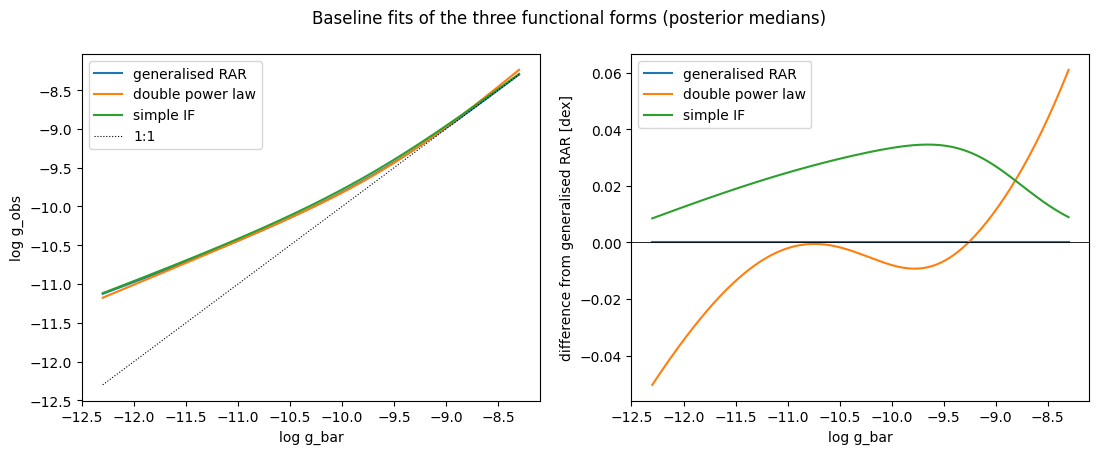

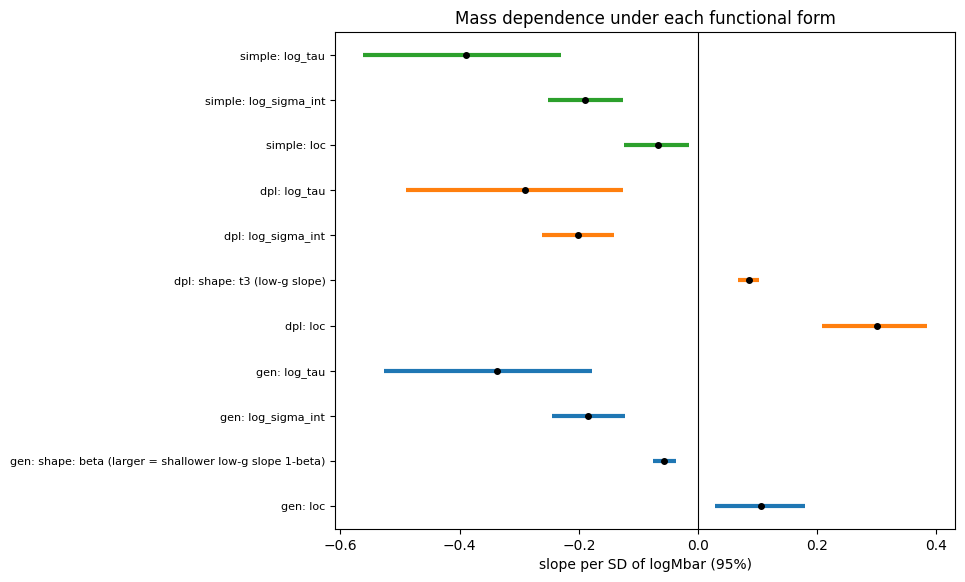

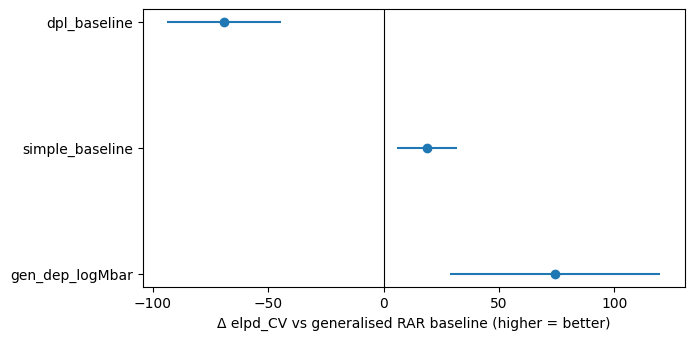

In [14]:
def savefig(fig, name):
    p = safe_path(OUT["figures"] / name); fig.savefig(p, dpi=130, bbox_inches="tight"); plt.show(); return p
# (1) the three fitted RAR forms (posterior medians of the baselines)
xg = np.linspace(-12.3, -8.3, 200); fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
med = lambda n, k: float(np.median(FULL[n]["samples"][k]))
curves = {}
if "samples" in FULL.get("gen_baseline", {}): curves["generalised RAR"] = np.asarray(mean_form("gen", jnp.asarray(xg), {"loc": med("gen_baseline", "log10_a0"), "shape": med("gen_baseline", "beta")}))
if "samples" in FULL.get("dpl_baseline", {}): curves["double power law"] = np.asarray(mean_form("dpl", jnp.asarray(xg), {"loc": med("dpl_baseline", "log10_t0"), "c": med("dpl_baseline", "c_dpl"), "t2": med("dpl_baseline", "t2_dpl"), "shape": med("dpl_baseline", "t3_dpl")}))
if "samples" in FULL.get("simple_baseline", {}): curves["simple IF"] = np.asarray(mean_form("simple", jnp.asarray(xg), {"loc": med("simple_baseline", "log10_g0")}))
for lab, cv_ in curves.items(): ax[0].plot(xg, cv_, label=lab); ax[1].plot(xg, cv_ - curves.get("generalised RAR", cv_), label=lab)
ax[0].plot(xg, xg, "k:", lw=0.8, label="1:1"); ax[0].set_xlabel("log g_bar"); ax[0].set_ylabel("log g_obs"); ax[0].legend()
ax[1].axhline(0, color="k", lw=0.6); ax[1].set_xlabel("log g_bar"); ax[1].set_ylabel("difference from generalised RAR [dex]"); ax[1].legend()
fig.suptitle("Baseline fits of the three functional forms (posterior medians)"); savefig(fig, "07_functional_forms.png")
# (2) mass-dependence slopes by form
if len(dep_tab):
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(dep_tab) + 1.5))
    for i, r in dep_tab.reset_index(drop=True).iterrows():
        ax.hlines(i, r.ci95_low, r.ci95_high, color={"gen": "C0", "dpl": "C1", "simple": "C2"}[r.form], lw=3); ax.plot(r.slope_per_SD_median, i, "ko", ms=4)
    ax.axvline(0, color="k", lw=0.8); ax.set_yticks(range(len(dep_tab))); ax.set_yticklabels([f"{r.form}: {r.parameter}" for r in dep_tab.itertuples()], fontsize=8)
    ax.set_xlabel(f"slope per SD of {DEP_COV} (95%)"); ax.set_title("Mass dependence under each functional form"); savefig(fig, "07_mass_dependence_by_form.png")
# (3) CV comparison
if len(cv_table) and "delta_vs_gen_baseline" in cv_table:
    t = cv_table.dropna(subset=["delta_vs_gen_baseline"])
    fig, ax = plt.subplots(figsize=(7, 0.6 * len(t) + 1.8)); ax.errorbar(t.delta_vs_gen_baseline, range(len(t)), xerr=t.delta_se, fmt="o")
    ax.axvline(0, color="k", lw=0.8); ax.set_yticks(range(len(t))); ax.set_yticklabels(t.model); ax.set_xlabel("Δ elpd_CV vs generalised RAR baseline (higher = better)")
    savefig(fig, "07_cv_comparison.png")

## 11. Exports and Report

In [15]:
pd.DataFrame(CHECKS).to_csv(OUT["diagnostics"] / "07_integrity_checks.csv", index=False)
config = {"run_id": RUN_ID, "created_utc": RUN_TIMESTAMP, "versions": VERSIONS, "notebook03_run_id": RUN03, "forms": FORMS, "alt_priors": ALT_PRIORS,
          "slope_prior_sd": SLOPE_SD, "dependence_covariate": DEP_COV, "full_fit_budget": FIT, "cv": {"folds": CV_FOLDS, "seed": CV_SEED, "models": CV_MODELS, "fit": CV_FIT, "pred": CV_PRED},
          "full_fits": {n: {"stats": r.get("stats"), "seconds": r.get("seconds"), "error": r.get("error")} for n, r in FULL.items()}, "resume_from": RESUME_FROM,
          "reference": "Desmond, Bartlett & Ferreira 2023, MNRAS (arXiv:2301.04368): compares the simple/standard/RAR IFs and a double power law; no single form recommended"}
(OUT["config"] / "07_validation_config.json").write_text(json.dumps(config, indent=2, default=str))
pd.DataFrame([{"package": k, "version": str(v)} for k, v in VERSIONS.items()]).to_csv(OUT["config"] / "07_package_versions.csv", index=False)
chk = pd.DataFrame(CHECKS)
fv = globals().get("FORM_VERDICT", {})
report = f"""# Notebook 07 — Functional-Form Sensitivity and Grouped Cross-Validation — Report

*Run {RUN_ID} ({RUN_TIMESTAMP} UTC); Notebook 03 run {RUN03}. This file exists only if the notebook ran.*

## Full-data fits (Model C error model)
{chr(10).join(f"* {r.fit}: converged={r.converged_by_all_criteria}; max R-hat {r.max_r_hat_all}; ESS {r.min_ess_bulk_all}/{r.min_ess_tail_all}; divergences {r.divergences}; {r.minutes:.1f} min" for r in full_status.itertuples())}

## Baseline parameters by form
{chr(10).join(f"* {r.fit} {r.parameter}: {r.median:.4f} [{r.ci95_low:.4f}, {r.ci95_high:.4f}]" for r in base_tab.itertuples())}

## Mass dependence by form (slope per SD of {DEP_COV})
{chr(10).join(f"* {r.form} {r.parameter}: {r.slope_per_SD_median:+.4f} [{r.ci95_low:+.4f}, {r.ci95_high:+.4f}], z = {r.z:+.2f}" for r in dep_tab.itertuples()) if len(dep_tab) else "* not available"}

**Functional-form verdict on the Notebook 06 'hints':** acceleration-scale trend has the same sign under all forms = {fv.get("acceleration_scale_trend_same_sign_all_forms")};
low-acceleration-slope trend has the same sign in the generalised RAR and the double power law = {fv.get("low_g_slope_trend_same_sign_gen_vs_dpl")}.
A trend that changes sign between forms is a functional-form artefact; a trend that keeps its sign is form-independent but, per Notebook 06,
must still be weighed against the correlated-noise null.

## Five-fold galaxy-grouped cross-validation (integrated held-out predictive density)
{chr(10).join(f"* {r['model']}: elpd_CV {r['elpd_cv']:.1f} (SE {r['se']:.1f})" + (f"; delta vs generalised baseline {r['delta_vs_gen_baseline']:+.1f} (SE {r['delta_se']:.1f}); better for {int(r['n_galaxies_better'])} galaxies" if pd.notna(r.get('delta_vs_gen_baseline', np.nan)) else "") for _, r in cv_table.iterrows()) if len(cv_table) else "* CV not run"}

## Caveats
* Model C (independent errors) throughout; the correlated-error models are too expensive to cross-validate here. Notebook 06 showed population trends under Model C are not robust to correlated noise.
* Priors for the alternative forms are broad documented choices (not specified by the proposal).
* CV training fits use a reduced sampler budget (2 chains x (500 + 750)); their quality is checked (divergences, key R-hat).

## Checks
{len(chk)} checks: {int((chk.status == "FAIL").sum())} FAIL, {int((chk.status == "WARN").sum())} WARN.
"""
rep = OUT["tables"] / "07_Validation_Report.md"; rep.write_text(report, encoding="utf-8")
manifest = pd.DataFrame([{"file": str(p.relative_to(OUT_ROOT)), "bytes": p.stat().st_size} for p in sorted(OUT_ROOT.rglob("*")) if p.is_file()])
manifest.to_csv(OUT["config"] / "07_output_manifest.csv", index=False)
print(report); print("Outputs:", OUT_ROOT)

# Notebook 07 — Functional-Form Sensitivity and Grouped Cross-Validation — Report

*Run 20261028T085455Z (2026-10-28T08:54:55Z UTC); Notebook 03 run 20261022T095735Z. This file exists only if the notebook ran.*

## Full-data fits (Model C error model)
* gen_baseline: converged=True; max R-hat 1.0045258458314705; ESS 3627.569725794483/1674.1804625851553; divergences 0; 5.5 min
* gen_dep_logMbar: converged=True; max R-hat 1.0044874903921197; ESS 1555.6957609309936/1199.0911187367437; divergences 0; 8.0 min
* dpl_baseline: converged=True; max R-hat 1.005894630085983; ESS 1958.551650222283/1502.724486920009; divergences 0; 10.1 min
* dpl_dep_logMbar: converged=True; max R-hat 1.0045376786204134; ESS 1369.89176668929/1647.1844140459355; divergences 0; 13.8 min
* simple_baseline: converged=True; max R-hat 1.003932067588038; ESS 3940.3266340953637/2119.1935321644164; divergences 0; 5.2 min
* simple_dep_logMbar: converged=True; max R-hat 1.0042847247501336; ESS 1544.6001685618928/1719.04293384